# Example 3.2: GA for 1D Unimodal Function Optimization
**Chapter 3 · Four Bar Mechanisms with Genetic Algorithms**

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

## Statement
Implement a real-coded GA to minimize the function:

$$f(x) = (x - 3.7)^2 + 0.5\,\sin(5x), \quad x \in [0, 10]$$

Use tournament selection of size 3, arithmetic crossover, and Gaussian mutation with `N_POP=30`, `N_GEN=60`, `Pm=0.08`.

**Objective:** verify that the GA converges to the global minimum and compare it with the reference solution obtained by fine grid search.

In [3]:
# ── Imports─────────────────────────────────────────────────────────
from numpy import *
import matplotlib.pyplot as plt
plt.rcParams.update({'font.family': 'serif', 'font.size': 12})

In [4]:
# ── Objective function ─────────────────────────────────────────────────────
def f_obj(x):
    return (x - 3.7)**2 + 0.5 * sin(5 * x)

random.seed(7)
N_POP, N_GEN = 30, 60
PM = 0.08

pop = random.uniform(0, 10, N_POP)
hist_best = []

for gen in range(N_GEN):
    fitness = array([f_obj(x) for x in pop])
    hist_best.append(fitness.min())
    # Selection by tournament (size 3)
    parents = []
    for _ in range(N_POP):
        candidates = random.choice(N_POP, 3, replace=False)
        parents.append(pop[candidates[argmin(fitness[candidates])]])
    parents = array(parents)
    # Arithmetic crossover
    children = []
    for i in range(0, N_POP - 1, 2):
        a = random.uniform(0, 1)
        children += [a*parents[i]+(1-a)*parents[i+1],
                     (1-a)*parents[i]+a*parents[i+1]]
    pop = clip(array(children[:N_POP]), 0, 10)
    # Gaussian mutation
    mask = random.rand(N_POP) < PM
    pop[mask] += random.normal(0, 0.3, mask.sum())
    pop = clip(pop, 0, 10)

best = pop[argmin(array([f_obj(x) for x in pop]))]
print(f"GA Solution:   x = {best:.4f},  f(x) = {f_obj(best):.4f}")

# Numerical reference (fine grid)
x_ref = linspace(0, 10, 10000)
idx_ref = argmin(f_obj(x_ref))
print(f"Reference:     x = {x_ref[idx_ref]:.4f},  f(x) = {f_obj(x_ref[idx_ref]):.4f}")
print(f"Absolute error in x: {abs(best - x_ref[idx_ref]):.4f}")
print(f"Convergence generation 1→{N_GEN}: {hist_best[0]:.3f} → {hist_best[-1]:.3f}")



GA Solution:   x = 3.4896,  f(x) = -0.4486
Reference:     x = 3.4893,  f(x) = -0.4486
Absolute error in x: 0.0002
Convergence generation 1→60: 0.110 → -0.449


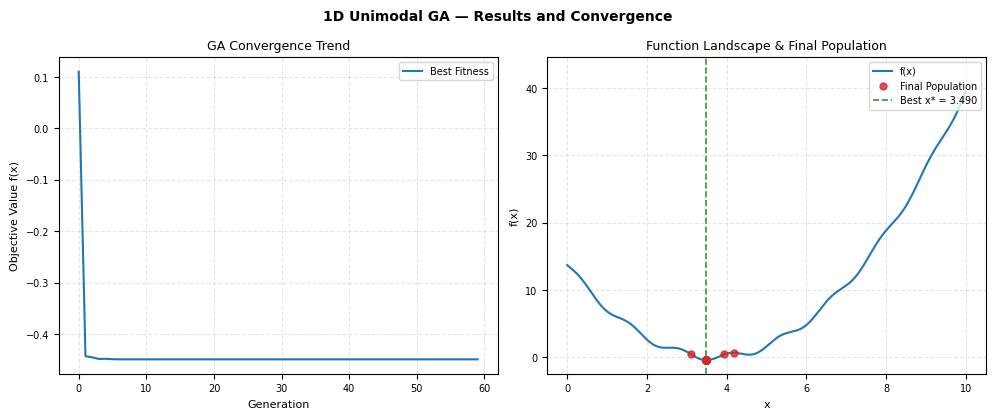

In [6]:
# ── Figure ───────────────────────────────────────────────────────────────
import os
import glob

# Dynamic filename extraction for Springer standards
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "ex3_2_ga_unimodal_function_1d"
except Exception:
    notebook_name = "ex3_2_ga_unimodal_function_1d"

# Publication quality parameters (Springer Style)
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['DejaVu Sans', 'Helvetica', 'Arial'],
    'font.size': 8,
    'axes.labelsize': 8,
    'axes.titlesize': 9,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'legend.fontsize': 7,
    'pdf.fonttype': 42,
    'ps.fonttype': 42
})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.2))

# Subplot 1: GA Convergence
ax1.plot(hist_best, color='#1f77b4', lw=1.5, label='Best Fitness')
ax1.set_xlabel('Generation')
ax1.set_ylabel('Objective Value f(x)')
ax1.set_title('GA Convergence Trend')
ax1.grid(True, linestyle='--', alpha=0.3)
ax1.legend(loc='upper right')

# Subplot 2: Function and Final Dispersion
x_plot = linspace(0, 10, 1000)
y_plot = [f_obj(xx) for xx in x_plot]
ax2.plot(x_plot, y_plot, color='#1f77b4', lw=1.5, label='f(x)')

# Final population plotting
pop_y = [f_obj(xx) for xx in pop]
ax2.scatter(pop, pop_y, color='#d62728', s=25, zorder=5, alpha=0.8, label='Final Population')
ax2.axvline(best, color='#2ca02c', ls='--', lw=1.2, label=f'Best x* = {best:.3f}')

ax2.set_xlabel('x')
ax2.set_ylabel('f(x)')
ax2.set_title('Function Landscape & Final Population')

# Dynamic margin adjustment to prevent annotation and label cropping
ax2.set_ylim(min(y_plot) - 2.0, max(y_plot) + 5.0)
ax2.grid(True, linestyle='--', alpha=0.3)
ax2.legend(loc='upper right')

plt.suptitle('1D Unimodal GA — Results and Convergence', fontsize=10, fontweight='bold')
plt.tight_layout()

# Double format export for publication
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()